In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
pd.set_option('display.max_columns', None)  # 设置显示最大列数

data = pd.read_csv('loan_net.csv', skipinitialspace=True)
target = data['flag'].copy()     # 选择自变量
data = data.iloc[:, :4].copy()   # 选择因变量
# 划分训练集和测试集
train_data, test_data, train_target, test_target = train_test_split(
    data, target, test_size=0.4, train_size=0.6 ,random_state=1234) 

In [2]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()   # 初始化模型
scaler.fit(train_data)  # 训练集训练模型
train_data = scaler.transform(train_data)  # 训练集标准化
# 使用训练集的均值、标准差对测试集进行标准化
test_data = scaler.transform(test_data)

### KNN

In [3]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

# 参数网格
param_grid = {
    'n_neighbors':list(range(1, 19, 2)),  # 近邻的数量k
}
# 网格搜索最优参数
knn = KNeighborsClassifier()
knn_cv = GridSearchCV(estimator=knn, param_grid=param_grid,
                      scoring='roc_auc', cv=4)
knn_cv.fit(train_data, train_target.values.flatten())
print('Best parameters generated by grid search: \n', knn_cv.best_params_)

Best parameters generated by grid search: 
 {'n_neighbors': 3}


In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.metrics import roc_curve, auc

# 绘制ROC、PR、KS曲线
def plot_metrics_curve(test_target, train_target, test_proba, train_proba):
    fpr_test, tpr_test, th_test = roc_curve(test_target, test_proba)
    fpr_train, tpr_train, th_train = roc_curve(train_target, train_proba)
    precision_test, recall_test, _ = precision_recall_curve(test_target, 
                                                            test_proba)
    precision_train, recall_train, _ = precision_recall_curve(train_target,
                                                              train_proba)
    
    #  ROC curve
    plt.figure(figsize=[6, 6])
    plt.subplot(221)
    plt.plot(fpr_test, tpr_test, 'b--')
    plt.plot(fpr_train, tpr_train, 'r-')
    plt.xlabel('fpr')
    plt.ylabel('tpr')
    plt.title('ROC curve:Test is dotted line')
    
    # PR curve
    plt.subplot(222)
    plt.plot(recall_test, precision_test, 'b--')
    plt.plot(recall_train, precision_train, 'r-')
    plt.xlabel('recall')
    plt.ylabel('precision')
    plt.title('PR curve:Test is dotted line')
    
    # KS curve, 曲线按阈值降序排列，所以需要1-threshold镜像
    plt.subplot(212)
    plt.plot(1 - th_test, tpr_test, 'b--', label='tpr') 
    plt.plot(1 - th_test, fpr_test, 'b:', label='fpr')
    plt.plot(1 - th_test, tpr_test - fpr_test, 'r-', label='tpr-fpr')
    plt.xlabel('score')
    plt.title('KS Curve  KS= %0.2f' %max(tpr_test - fpr_test))
    legend = plt.legend(loc='upper left', shadow=True, fontsize='x-large')
    
    plt.tight_layout()
    plt.show()
    
    # 打印auc与平均准确率指标
    print('TestAUC=%.4f,' %auc(fpr_test, tpr_test),
          'TrainAUC=%.4f' %auc(fpr_train, tpr_train))

    print('TestAP=%.4f,'%average_precision_score(test_target,test_proba),
          'TrainAP=%.4f'%average_precision_score(train_target,train_proba))

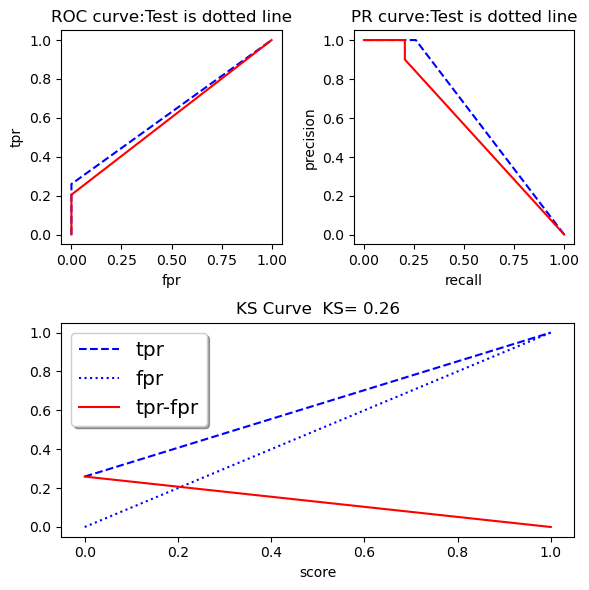

TestAUC=0.6296, TrainAUC=0.6022
TestAP=0.2611, TrainAP=0.2067


In [5]:
best_knn = knn_cv.best_estimator_
# 预测概率
test_proba = best_knn.predict_proba(test_data)[:, 1]  
train_proba = best_knn.predict_proba(train_data)[:, 1]

# 绘制评估图形
plot_metrics_curve(test_target, train_target, test_proba, train_proba)     

### 朴素贝叶斯

In [6]:
import pandas as pd

data = pd.read_csv('loan_net.csv', skipinitialspace=True)
data.describe(include="all")

,net_size,degree,average_neighbor_degree,percentage,flag
count,27321.000000,27321.000000,27321.000000,27321.000000,27321.000000
mean,2.299660,1.259178,1.026988,0.001998,0.002599
std,0.639697,0.443423,0.166580,0.024629,0.050912
min,2.000000,1.000000,1.000000,0.000000,0.000000
25%,2.000000,1.000000,1.000000,0.000000,0.000000
50%,2.000000,1.000000,1.000000,0.000000,0.000000
75%,3.000000,2.000000,1.000000,0.000000,0.000000
max,20.000000,6.000000,4.500000,0.500000,1.000000


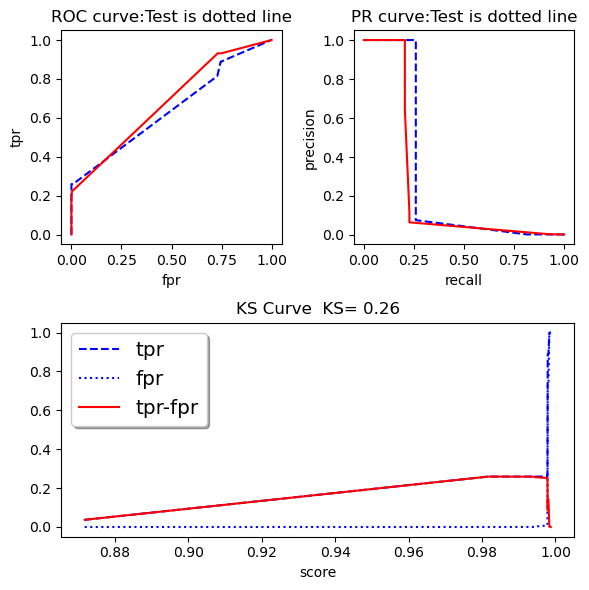

TestAUC=0.6438, TrainAUC=0.6798
TestAP=0.2613, TrainAP=0.2098


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB

target = data['flag'].copy()     # 选择自变量
data = data.iloc[:, :4].copy()   # 选择因变量

# 划分训练集和测试集
train_data, test_data, train_target, test_target = train_test_split(
    data, target, test_size=0.4, train_size=0.6 ,random_state=1234) 

# 建模
nb= MultinomialNB()
nb.fit(train_data, train_target.values.flatten())

# 预测
test_proba = nb.predict_proba(test_data)[:, 1]  
train_proba = nb.predict_proba(train_data)[:, 1]

# 评估
plot_metrics_curve(test_target, train_target, test_proba, train_proba)  

### svm

In [8]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
pd.set_option('display.max_columns', None)  # 设置显示最大列数

data = pd.read_csv('loan_net.csv', skipinitialspace=True)
target = data['flag'].copy()     # 选择自变量
data = data.iloc[:, :4].copy()   # 选择因变量
# 划分训练集和测试集
train_data, test_data, train_target, test_target = train_test_split(
    data, target, test_size=0.4, train_size=0.6 ,random_state=1234) 
scaler = StandardScaler()   # 初始化模型
scaler.fit(train_data)  # 训练集训练模型
train_data = scaler.transform(train_data)  # 训练集标准化
# 使用训练集的均值、标准差对测试集进行标准化
test_data = scaler.transform(test_data)

In [9]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

# 设置参数搜索空间
param_grid = {
    'gamma': np.arange(0.01, 1, 0.1),  # 核函数的系数
    'kernel':('linear', 'rbf'),        # 核函数
    'C': np.arange(0.01, 1.0, 0.1),    # 正则化系数的倒数
}

# 参数网格搜索
svc = SVC(probability=True)  # 设置模型可产生概率值
svc_cv = GridSearchCV(estimator=svc, param_grid=param_grid, 
                      scoring='roc_auc', cv=4)
svc_cv.fit(train_data, train_target)
print("Best parameters is :\n{}".format(svc_cv.best_params_))

Best parameters is :
{'C': 0.11, 'gamma': 0.01, 'kernel': 'rbf'}


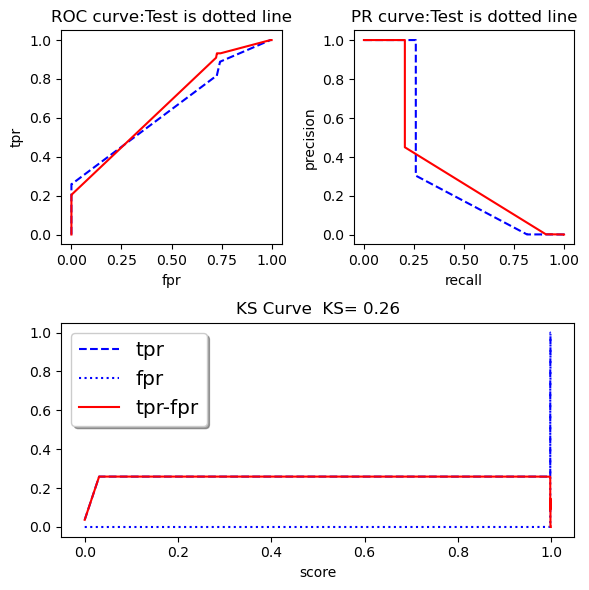

TestAUC=0.6480, TrainAUC=0.6695
TestAP=0.2613, TrainAP=0.2072


In [11]:
best_svc = svc_cv.best_estimator_

# 预测概率
test_proba = svc_cv.predict_proba(test_data)[:, 1]  
train_proba = svc_cv.predict_proba(train_data)[:, 1]

# 绘制评估图形，plot_metrics_curve已预定义
plot_metrics_curve(test_target, train_target, test_proba, train_proba)    

### MLP

In [12]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.neural_network import MLPClassifier
from scipy.stats import randint, uniform

# 随机搜索迭代次数
n_iter = 20

# 设置参数分布
param_distributions = {
    'hidden_layer_sizes':[(10, ), (15, ), (5, 5)], # 网络结构参数
    'activation':['logistic', 'relu'],             # 激活函数
    'alpha':uniform(0.01, 10)                      # 正则化强度
}

# 参数优化、建模
mlp = MLPClassifier(max_iter=1000)
mlp_cv = RandomizedSearchCV(
    estimator=mlp,
    param_distributions=param_distributions, 
    n_iter=n_iter,
    scoring='roc_auc', 
    cv=4
)
mlp_cv.fit(train_data, train_target)
print("Best parameters is :\n{}".format(mlp_cv.best_params_)) # 不同初始化条件导致每次运行结果不固定

C:\Users\15587\AppData\Roaming\Python\Python39\site-packages\sklearn\model_selection\_search.py:409: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  arr = np.array(param_list)


Best parameters is :
{'activation': 'logistic', 'alpha': 7.273514414472142, 'hidden_layer_sizes': (15,)}


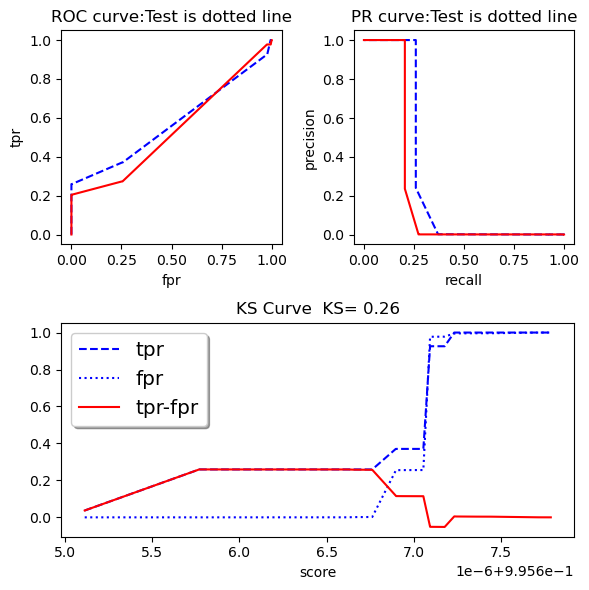

TestAUC=0.5702, TrainAUC=0.5347
TestAP=0.2611, TrainAP=0.2067


In [13]:
best_mlp = mlp_cv.best_estimator_ 

# 预测概率
test_proba = best_mlp.predict_proba(test_data)[:, 1]  
train_proba = best_mlp.predict_proba(train_data)[:, 1]

# 绘制评估图形，plot_metrics_curve已预定义
plot_metrics_curve(test_target, train_target, test_proba, train_proba)    